# Lab 3 - Deep Learning
## Ava Everett (49136678) and Jay Lu ()

## Deep Learning Framework. 
*Demonstrate conceptual understanding of a deep learning workflow. Without assistance from an LLM, explain the role of the following PyTorch components:*

- **Dataset (in Pytorch)**: An abstract class that represents the imported dataset. Argument of the DataLoader constructor; stores every sample from the data and its respective labels. There are two types of datasets: map-style datasets and iterable-style datasets. 
- **Data Loader**: A class that allows the program to iterate through a dataset in determined batches. It also provides the framework to use a variety of multiprocessing functions, and it can be used to train a model.
- **Model Class (nn.Module)**: The base class for all neural network modules; registers parameters and, if they have weights, will express them via instances of torch.nn.Parameter. Has an init and forward function for initialization and computation, respectively.
- **Loss Function**: Measure how well the model's predicted value is to the target value. Can be used to optimize output and gauge how well/poorly a model is doing. 
- **Optimizer**: A specific version of an optimization algorithm to update a neural network's parameters. There are a few available in PyTorch (e.g., Adam, Adagrad, SGD), but you can build your own custom optimizer for specific problems.
- **Training Loop (Providing Training Data to Model)**: Feeds the sample data to the model for the optimizer to tune the model's parameters. Works by grabbing a batch of data from the DataLoader, performs its predictions, calculates the loss on the predictions and the actual data, backpropagates, adjusts the model's learning weights based on the new observations, and reports the loss. It works in epochs, which are passes through the entire dataset, validating and saving a copy of the model each time. Model must be set to training mode during this time. 
- **Validation Loop (Providing Data to Evaluate the Model)**: Is inside the epoch loop, only does a forward pass and loss calculation (aka: no backprop). Helps with detection of overfitting, tuning hyperparameters, and letting the user see when is the best point to stop the training of the model. Model must be set to evaluation mode during this time. 

## Training Pipeline
*Using an LLM, generate starter code that constructs the training pipeline for your dataset and model. The pipeline should allow at least two ways of providing data to your model: (1) all data can be provided to a model as a single input and (2) modalities of data can be provided to the model as separate parallel inputs. When using an LLM, you should provide the prompt used, identify one aspect of the generated pipeline that was modified by your team, and explain why the modification was necessary.*

In [1]:
# importing dataset - Anime Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print ('Pandas:', pd.__version__)
print('Numpy:', np.__version__)

df = pd.read_csv('https://raw.githubusercontent.com/Lu-Rin-e/CS5324-Machine-Learning-Labs/refs/heads/main/anime_dataset_20k.csv')
df.head()


Pandas: 2.2.2
Numpy: 1.26.4


,mal_id,anilist_id,title_english,title_romaji,title_japanese,title_synonyms,type,source,status,age_rating,...,is_disney_plus,is_hulu,is_vrv,is_bilibili,is_youtube,num_platforms,score_tier,popularity_tier,synopsis,image_url
0,1,1.0,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,NaN,TV,original,finished_airing,r,...,False,True,False,False,False,6,Great,Top 100,"Crime is timeless. By the year 2071, humanity ...",https://cdn.myanimelist.net/images/anime/4/196...
1,5,5.0,Cowboy Bebop: The Movie,Cowboy Bebop: Tengoku no Tobira,カウボーイビバップ 天国の扉,Cowboy Bebop: Knockin' on Heaven's Door,MOVIE,original,finished_airing,r,...,False,False,False,False,False,0,Great,Top 1K,"Another day, another bounty—such is the life o...",https://cdn.myanimelist.net/images/anime/1439/...
2,6,6.0,Trigun,Trigun,トライガン,NaN,TV,manga,finished_airing,pg_13,...,False,False,False,False,False,1,Great,Top 500,"Vash the Stampede is the man with a $$60,000,0...",https://cdn.myanimelist.net/images/anime/1130/...
3,7,7.0,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),WHR,TV,original,finished_airing,pg_13,...,False,False,False,False,False,1,Good,Top 5K,"Though hidden away from the general public, Wi...",https://cdn.myanimelist.net/images/anime/10/19...
4,8,8.0,Beet the Vandel Buster,Bouken Ou Beet,冒険王ビィト,Adventure King Beet,TV,manga,finished_airing,pg,...,False,False,False,False,False,0,Average,Niche,It is the dark century and the people are suff...,https://cdn.myanimelist.net/images/anime/7/215...


Our main goal will be to get the model to accurately predict the popularity tier of a show (e.g., Niche, Top 5K, Top 1k, Top 500, and Top 100). 

Since just about all of the non tv/movies are niche, this set will isolate tv shows and movies. We will also remove all adult/explicit anime.

In [2]:
# Removing Adult/Explicit Anime
df = df[df.is_adult == False]

#Removing is_adult column
del df['is_adult']

# Removing all items that aren't TV shows or Movies
df = df[(df.type == 'TV') | (df.type == 'MOVIE')]

Let's see the split of the data

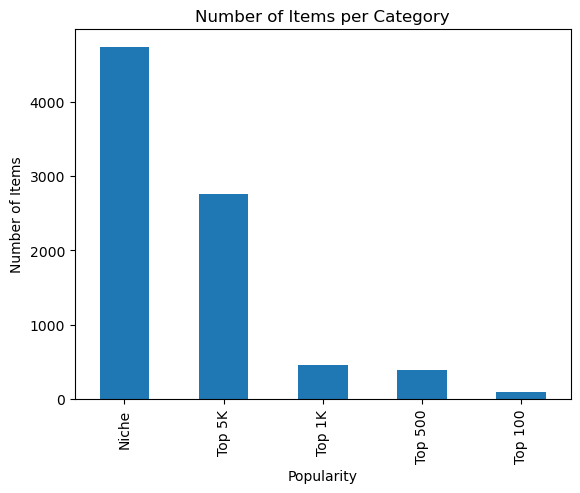

In [3]:
df['popularity_tier'].value_counts().plot(kind="bar")

plt.xlabel("Popularity")
plt.ylabel("Number of Items")
plt.title("Number of Items per Category")
plt.show()

We'll be consolidating Top 1K, Top 500, and Top 100 into one category, as they are too small by themselves.

In [4]:
df['popularity_tier'] = df['popularity_tier'].replace('Top 100', 'Top 1K')
df['popularity_tier'] = df['popularity_tier'].replace('Top 500', 'Top 1K')

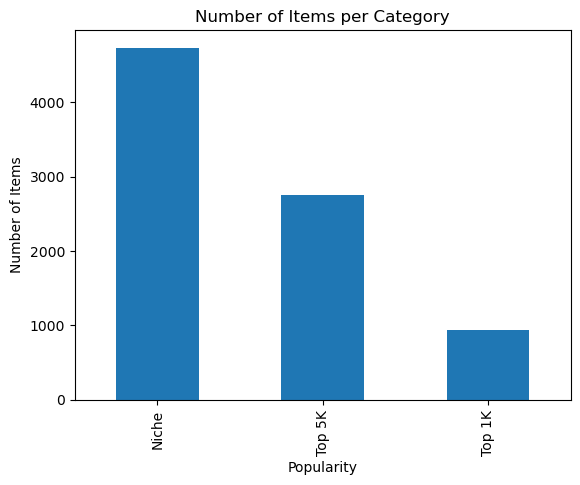

In [5]:
df['popularity_tier'].value_counts().plot(kind="bar")

plt.xlabel("Popularity")
plt.ylabel("Number of Items")
plt.title("Number of Items per Category")
plt.show()

With that settled, let's start cleaning up the data more. 

1 - As we're predicting popularity, all popularity-related categories must be removed to prevent data leaking (aka: MAL popularity, MAL members, MAL favorites, anilist popularity, anilist favorites). All non-relevant categories/difficult to parse categories will also be removed (ie: anime title, synopsis, etc.)
2 - We need to multi-hot encode the genres AND convert score_tier and popularity_tier to integers

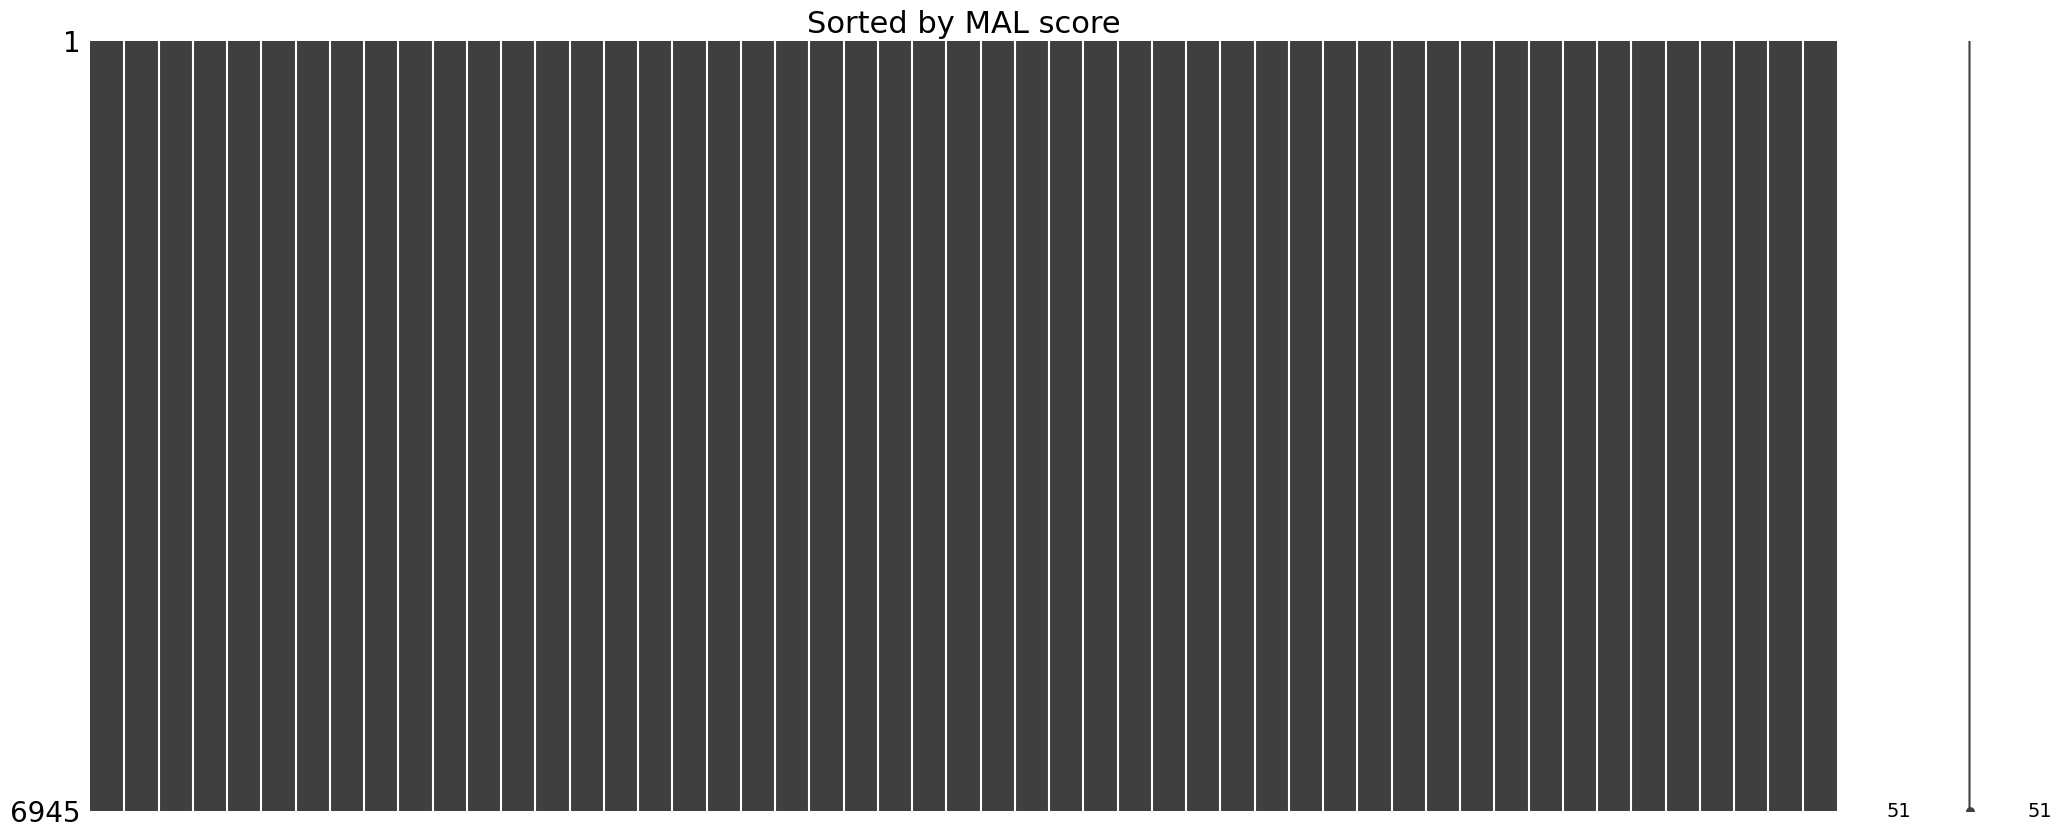

In [6]:
keep_cols = ['type', 'source', 'status','age_rating','season', 'year', 'episodes','duration_min', 'mal_score', 'anilist_score', 'score_gap_mal_anilist','studio_main', 'num_platforms', 'score_tier', 'popularity_tier', 'genres']
df = df[keep_cols]
# Drop rows with missing values
df = df.dropna(subset=keep_cols)
#Multi-hot Encoding the Genres; they are currently one object
from sklearn.preprocessing import MultiLabelBinarizer

genre_lists = df['genres'].str.split('|').apply(lambda lst: [g.strip() for g in lst])

mlb = MultiLabelBinarizer()
genre_encoded = pd.DataFrame(
    mlb.fit_transform(genre_lists),
    columns=mlb.classes_,
    index=df.index
)

# The dataset combined MAL Themes, MAL Genres, and Demographics into genres. Just keeping the Genres and Demographics
genres_to_keep = [
    'Action', 'Adventure', 'Avant Garde', 'Boys Love',
    'Comedy', 'Drama', 'Fantasy', 'Girls Love', 'Gourmet', 'Horror',
    'Mystery', 'Romance', 'Sci-Fi', 'Slice of Life', 'Sports',
    'Supernatural', 'Suspense', 'Josei', 'Kids', 'Seinen', 'Shoujo', 'Shounen'
]

# Filtering the encoded columns before merging into dataframe
genre_encoded = genre_encoded[[col for col in genre_encoded.columns if col in genres_to_keep]]

df = pd.concat([df, genre_encoded], axis=1)



#Getting rid of old genres column
del df['genres']


# One-hot encode type and source (currently strings)
df = pd.get_dummies(df, columns=['type', 'source'], drop_first=True)

#Encode popularity tier and score tier

score_map = {"Poor": 0, "Average": 1, "Good": 2, "Great": 3, "Masterpiece": 4}


df["score_tier_int"] = df["score_tier"].map(score_map)


#Now, we can remove the old score tier
del df['score_tier']


#Checking what the cleaned data looks like
df.to_csv('animecleaned3.csv', index=False)

#Checking to make sure there is no missing data
import missingno as mn
mn.matrix(df.sort_values(by=['mal_score']))
plt.title("Sorted by MAL score", fontsize=22)
plt.show()



With all the data cleaned, let's move on to creating the pipeline!

Agent Used: Microsoft Copilot 

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Target indices: Niche=0, Top 5K=1, Top 1K=2.
label_map = {"niche": 0, "top 5k": 1, "top 1k": 2}
y_names = df["popularity_tier"].astype(str).str.strip().str.lower()
unknown = sorted(set(y_names) - set(label_map))
if unknown:
    raise ValueError(f"Unexpected popularity_tier values: {unknown}")
y = y_names.map(label_map).to_numpy(dtype=np.int64)

numeric_cols = ["year", "episodes", "duration_min", "mal_score", "anilist_score",
                "score_gap_mal_anilist", "num_platforms"]
categorical_cols = ["status", "age_rating", "season", "studio_main"]
binary_cols = [c for c in df if c.startswith(("type_", "source_"))]
genre_cols = ["Action", "Adventure", "Avant Garde", "Boys Love", "Comedy", "Drama",
              "Fantasy", "Girls Love", "Gourmet", "Horror", "Josei", "Kids",
              "Mystery", "Romance", "Sci-Fi", "Seinen", "Shoujo", "Shounen",
              "Slice of Life", "Sports", "Supernatural", "Suspense"]
required = numeric_cols + categorical_cols + binary_cols + genre_cols + ["popularity_tier"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Missing cleaned-data columns: {missing}")

# Split before fitting transforms to prevent validation-data leakage.
train_idx, val_idx = train_test_split(np.arange(len(df)), test_size=0.2,
                                      random_state=42, stratify=y)
train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

scaler = StandardScaler()
numeric_train = scaler.fit_transform(train_df[numeric_cols]).astype(np.float32)
numeric_val = scaler.transform(val_df[numeric_cols]).astype(np.float32)
encoder = OneHotEncoder(handle_unknown="ignore")
category_train_encoded = encoder.fit_transform(train_df[categorical_cols]).toarray()
category_val_encoded = encoder.transform(val_df[categorical_cols]).toarray()
category_train = np.concatenate((category_train_encoded,
                                 train_df[binary_cols].to_numpy(dtype=np.float32)), axis=1)
category_val = np.concatenate((category_val_encoded,
                               val_df[binary_cols].to_numpy(dtype=np.float32)), axis=1)
genre_train = train_df[genre_cols].to_numpy(dtype=np.float32)
genre_val = val_df[genre_cols].to_numpy(dtype=np.float32)
y_train, y_val = y[train_idx], y[val_idx]

class AnimeDataset(Dataset):
    """Yield one concatenated tensor or separate tensors for each modality."""
    def __init__(self, numeric, categorical, genres, labels, input_mode="single"):
        if input_mode not in ("single", "parallel"):
            raise ValueError("input_mode must be 'single' or 'parallel'")
        self.input_mode = input_mode
        self.modalities = {
            "numeric": torch.tensor(numeric, dtype=torch.float32),
            "categorical": torch.tensor(categorical, dtype=torch.float32),
            "genres": torch.tensor(genres, dtype=torch.float32),
        }
        self.features = torch.cat(list(self.modalities.values()), dim=1)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        if self.input_mode == "parallel":
            return {name: values[index] for name, values in self.modalities.items()}, self.labels[index]
        return self.features[index], self.labels[index]

train_dataset_single = AnimeDataset(numeric_train, category_train, genre_train, y_train)
val_dataset_single = AnimeDataset(numeric_val, category_val, genre_val, y_val)
train_dataset_parallel = AnimeDataset(numeric_train, category_train, genre_train, y_train, "parallel")
val_dataset_parallel = AnimeDataset(numeric_val, category_val, genre_val, y_val, "parallel")

# True gives batches of modality tensors; False gives one concatenated feature tensor.
use_parallel_inputs = True
train_dataset = train_dataset_parallel if use_parallel_inputs else train_dataset_single
val_dataset = val_dataset_parallel if use_parallel_inputs else val_dataset_single
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

print("Class mapping:", label_map)
print("Train/validation rows:", len(train_dataset), len(val_dataset))
print("Single input width:", train_dataset_single.features.shape[1])
print("Parallel modality widths:", {name: x.shape[1] for name, x in train_dataset_parallel.modalities.items()})